# Analysis of Naturalistic Memory Experiment

This notebook performs analyses on a naturalistic movie-watching memory experiment with two children viewing home videos and recreates figures in the manuscript.

Note: p values (and z-scores created through bootstrapping or randomization) may differ from those reported in the manuscript because of random seeds.

**Table of Contents**
>[Set up](#setup)  
>[Participant information](#descriptives)      
>[Create MTL files](#create_files)      
>[Self vs. Other in the hippocampus](#selfother_hipp)    
>[Self vs. Other in the whole brain](#selfother_whole)  

## Set up <a id='setup'></a> 

Load packages and define some useful functions.

In [2]:
## Create the functions needed to analyze the results 
import numpy as np
import os
import glob
import nibabel as nb
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns
import scipy
from scipy import stats
from scipy.io import loadmat
import matplotlib
import pandas as pd
from nilearn import plotting
import nibabel as nib
from nilearn.input_data import NiftiMasker
import itertools
import warnings
import pickle
warnings.filterwarnings('ignore')

%matplotlib inline
%autosave 5

# Get the base directory
curr_dir = os.getcwd()
os.chdir('../../') # Move into the infant neuropipe root
base_dir = os.getcwd() + '/'
os.chdir(curr_dir) # Come back

# where are the subfield segmentations stored? 
mtl_location = 'Subfield_MTL_Segmentations/' # full path ommitted 

# Plotting colors 
color_palettes = dict({'three_yo':sns.color_palette('light:#CC2936',3)[1:],
                       'nine_yo':sns.color_palette('light:#5CB5B3',3)[1:]})

# name of the FEAT file we are considering 
FEAT='Saycam_IND_15s_inc_contrasts_Z.feat' # output GLM from first level 
num_zstats=240 # total number of z-statistics = 120 movies x 2 halves, hard coded 

# Reminder of the subfields (values in the actual nifti are these +1)
subfield_idx_dict=dict({'CA1':0,'CA2':1,'CA3':2,'DG':3,'Sub':4,'Tail':5})
subregion_idx_dict=dict({'ErC':6,'PrC_35':7,'PrC_36':8,'PhC':9})

# Whole brain t-statistic value 
tval=3.1

# who are the participants
participants=['three_yo','nine_yo']

# load the hash ID dictionary linking to participant IDs
with open("hash_id_dict.pkl", "rb") as file:
    hash_id_dict = pickle.load(file)
    

Autosaving every 5 seconds


### Define functions 

In [3]:
def bootstrap_dist(data,null_vall=0,nPerm=1000):
    '''Bootstrap resampling for the mean of the data'''
    
    perm_dist=[]
    for perm in range(nPerm):
        sampidx=np.random.choice(np.arange(len(data)),len(data),replace=True)
        randomsamp=np.array(data)[sampidx]
        perm_dist.append(np.mean(randomsamp))
    
    return perm_dist

def bootstrap_corr(data,null_vall=0,nPerm=1000):
    '''Bootstrap resampling for the Correlation of the data'''
    
    perm_dist=[]
    for perm in range(nPerm):
        sampidx=np.random.choice(np.arange(len(data)),len(data),replace=True)
        randomsamp=np.array(data)[sampidx]
        perm_dist.append(np.mean(randomsamp))
    
    return perm_dist

def get_QAs(func_run,session):
    
    '''Get the QA information from the raw scans'''
    
    # Get the functional name (do it differently if it is a pseudorun)
    if len(func_run) == 2:
        func_name = glob.glob('%s/subjects/%s/data/nifti%s/*_functional%s.nii.gz' % (base_dir,hash_id_dict[ppt],session,func_run))
    else:
        func_name = glob.glob('%s/subjects/%s/analysis/firstlevel/pseudorun/*_functional%s.nii.gz' % (base_dir,hash_id_dict[ppt],func_run))
    
    # Get the number of TRs per run 
    nii = nib.load(func_name[0])
    
#     print('Functional run %s has %d TRs' % (func_run, nii.shape[3]))
    
    # Extract the sfnr from the QA
    QA_Filename = glob.glob('%s/subjects/%s/data/qa%s/qa_events_*_functional%s.bxh.xml' % (base_dir,hash_id_dict[ppt],session,func_run));
    
    # if it exists 
    if len(QA_Filename) > 0:
        
        # Open the file and find the secions that define SNR and SFNR
        fid = open(QA_Filename[0], 'r')
        lines = fid.readlines()

        for line in lines:
            if line.find('mean_snr_middle_slice') > -1:
#                 print('QA SNR: %s' % line[line.find('>') + 1:line.find('</')])
                snr=line[line.find('>') + 1:line.find('</')]
            elif line.find('mean_sfnr_middle_slice') > -1:
#                 print('QA SFNR: %s' % line[line.find('>') + 1:line.find('</')])
                sfnr=line[line.find('>') + 1:line.find('</')]

        fid.close()
    else:
        print('No QA file found')

    return float(snr), float(sfnr), nii.shape[3]

# segment the data 
def segment_data(ppt,segmentation_name,FEAT,zstat):

    # get directories
    subject_dir = base_dir + 'subjects/' + ppt
    data_dir = '%s/analysis/secondlevel_Saycam/default' % subject_dir
    feat_dir =f"{data_dir}/{FEAT}/stats"

    # get the zstat data (and reshape)
    functional_name=f"{feat_dir}/zstat{zstat}_registered_highres.nii.gz" # must be registered to highres
    functional = nib.load(functional_name).get_fdata()
    functional = functional.reshape((functional.shape[0], functional.shape[1], functional.shape[2], 1))

    # get the segmentation file 
    segmentation = nib.load(segmentation_name).get_fdata()
   
    roi_labels = [1,2,3,4,5,6,7,8,9,10] # these are the ROI labels we care about 

    masked_data = np.zeros((functional.shape[3], len(roi_labels)))    # preset 
    for mask_counter, mask_val in enumerate(roi_labels):

        # Make the mask of the segmentation
        masked_segmentation = segmentation == mask_val

        # Average all the voxels in the mask matching these values
        masked_data[:, mask_counter] = np.mean(functional[masked_segmentation], 0)
    return masked_data

## Participant Information <a id='descriptives'></a> 
This study had two participants: a 3 year old and a 9 year old.

In [4]:
# First, get information about participant behavior

for ppt in participants:
    print(ppt)
    
    # load the mat file that has the analyzed data 
    data_file = '%s/subjects/%s/analysis/Behavioral/AnalysedData.mat' %(base_dir,hash_id_dict[ppt])
    analysedData=loadmat(data_file,struct_as_record=False)['AnalysedData'][0][0]
      
    # specifically look at the saycam experiment
    saycam_data = analysedData.__dict__['Experiment_Saycam'][0][0].__dict__
    
    prop_trs_exclude = []
    prop_eye_exclude = []
    
    # cycle through blocks of the data to get the amount of TRs excluded for motion and eyetracking frames excluded for eyes closed
    for block in saycam_data['_fieldnames']:

        eye_excluded = saycam_data[block][0][0].__dict__['Proportion_EyeTracking_Excluded']
        trs_excluded = saycam_data[block][0][0].__dict__['Proportion_TRs_Excluded_Events']

        # skip the first instance of block 8 for the three year old which is excluded
        if ppt == 'three_yo':
            if block != 'Block_8_1':
                prop_trs_exclude.extend(trs_excluded[0])
                prop_eye_exclude.extend(eye_excluded[:,0])
        else:
            
            prop_trs_exclude.extend(trs_excluded[0])
            prop_eye_exclude.extend(eye_excluded[:,0])
            
    # Get the appropriate fields for looking at eyetracking reliability
    eyedata_idxs = analysedData.__dict__['EyeData'][0][0].__dict__['Idx_Names'][0][0].__dict__['Saycam']
    timecourses = analysedData.__dict__['EyeData'][0][0].__dict__['Timecourse'][0][0].__dict__['Saycam'][0]
    reliabilities = analysedData.__dict__['EyeData'][0][0].__dict__['Reliability'][0][0].__dict__['Saycam'][0][0].__dict__['Intraframe'][0][0]
    
    all_prop_onscreen = []
    all_reliabilities = [] 
    
    # cycle through trials (aka movies) to get IRRs and proportion looking on screen 
    for t, trial in enumerate(timecourses):

        prop_looking_onscreen = sum(trial[0]==5)/len(trial[0])

        trial_irr = reliabilities[t,0]
        
        block_name = 'Block_%s_%s' % (eyedata_idxs[t][0],eyedata_idxs[t][1])

        # skip the first instance of block 8 for three yo which is excluded 
        if ppt == 'three_yo':
            if block != 'Block_8_1':
                all_prop_onscreen.append(prop_looking_onscreen)
                all_reliabilities.append(trial_irr)

        else:
            all_prop_onscreen.append(prop_looking_onscreen)
            all_reliabilities.append(trial_irr)
        
    # print the information! 
    print('TRs included:',1-np.mean(np.array(prop_trs_exclude)))
    print('Eye included (includes undetected values):',1-np.mean(np.array(prop_eye_exclude)))
    print('Prop looking on-screen:',np.mean(np.array(all_prop_onscreen)))
    print('Mean IRR:',np.mean(all_reliabilities))
    
    print()
    

three_yo
TRs included: 0.996374007936508
Eye included (includes undetected values): 0.9179749655968212
Prop looking on-screen: 0.882816511602521
Mean IRR: 0.9736058878969431

nine_yo
TRs included: 0.9844121430470114
Eye included (includes undetected values): 0.9667311782562806
Prop looking on-screen: 0.9466503662046092
Mean IRR: 0.9870578638534897



In [5]:
# Calculate the snr and sfnr across functional runs  
for ppt in participants:
    
    all_snr=[]
    all_sfnr=[]
    
    # if ppt is the three yo, there were two sessions across two days 
    if ppt=='three_yo':
        sessions=['_session1','_session2']
    else:
        sessions=['']
        
    # cycle through sessions
    for session in sessions:

        runs =  glob.glob('%s/subjects/%s/data/nifti%s/*_functional??.nii.gz' % (base_dir, hash_id_dict[ppt], session))  # Works for both runs and pseudo runs

        # cycle through the functional runs 
        for run in runs:
            func_run = run[run.find('functional') + 10:run.find('.nii.gz')]
            snr,sfnr,nTRs=get_QAs(func_run,session) # get the SNR and SFNR 
            all_snr.append(snr)
            all_sfnr.append(sfnr)

            
    print(ppt)
    print('SNR: M = %0.3f (SD = %0.3f)' % (np.mean(all_snr),np.std(all_snr)))
    print('SFNR: M = %0.3f (SD = %0.3f)'% (np.mean(all_sfnr),np.std(all_sfnr)))
    
    print()

three_yo
SNR: M = 55.290 (SD = 9.776)
SFNR: M = 48.000 (SD = 9.940)

nine_yo
SNR: M = 45.660 (SD = 6.976)
SFNR: M = 36.980 (SD = 7.950)



In [6]:
## Count the number of voxels in the whole brain and hippocampus

# cycle through participants 
for ppt in participants:
    
    # get the whole brain file
    highres_file=nib.load('%s/subjects/%s/analysis/secondlevel/registration_ANTs/mask.nii.gz' %(base_dir,hash_id_dict[ppt]))

    # number of voxels (equivalent to the mm cubed!)
    whole_vox = np.sum(highres_file.get_fdata()>0)
    
    # print the whole brain voxels
    print('%s number of voxels (whole brain) = %d' %(ppt,whole_vox))
        
    # cycle through hemispheres
    for hemi in ['Left','Right']:
        
        # lower case for nine year old, for some reasons 
        if ppt =='nine_yo':
            hemi = hemi.lower()
        
        # get the segmentation -- as was done in the TSE space 
        segmentation = nib.load('%s/%s_%s_hippocampus_MTL.nii.gz' % (mtl_location,hash_id_dict[ppt],hemi))
        
        # print the number of MTL voxels
        # coding scheme was such that values under 7 are hippocampus, over 7 are MTL 
        hipp_vox = np.sum((segmentation.get_fdata()<7)*(segmentation.get_fdata()>0))
        mtl_vox = np.sum((segmentation.get_fdata()>=7))
        
        # print the total number of voxels 
        print('%s number of voxels (%s): hipp = %d, mtl = %d' %(ppt,hemi,hipp_vox,mtl_vox))
        
        # turn into mm cubed (from the TSE sequence pixel dimensions)
        hipp_mm = 0.437500*0.437500*1.8*hipp_vox
        mtl_mm = 0.437500*0.437500*1.8*mtl_vox
        
        print('%s mm cubed: hipp = %0.2f, mtl = %0.2f' %(ppt,hipp_mm,mtl_mm))
    print()
        

three_yo number of voxels (whole brain) = 1423446
three_yo number of voxels (Left): hipp = 8098, mtl = 14634
three_yo mm cubed: hipp = 2790.01, mtl = 5041.87
three_yo number of voxels (Right): hipp = 7637, mtl = 15405
three_yo mm cubed: hipp = 2631.19, mtl = 5307.50

nine_yo number of voxels (whole brain) = 1373504
nine_yo number of voxels (left): hipp = 7350, mtl = 11915
nine_yo mm cubed: hipp = 2532.30, mtl = 4105.09
nine_yo number of voxels (right): hipp = 7729, mtl = 10387
nine_yo mm cubed: hipp = 2662.88, mtl = 3578.65



## Create MTL files <a id='create_files'></a> 
Segment the functional data so that we can analyze the resulting z-statistics

In [7]:
# Cycle through participants 
for ppt in participants: 

    # where the aligned highres segmentations exist
    mask_files=(glob.glob(mtl_location+'/'+hash_id_dict[ppt]+'*realigned_NN.nii.gz'))

    # cycle through segmentations (left or right side)
    for segmentation_name in mask_files:

        if str.find(segmentation_name, 'ight') ==-1:
            Side='Left'
        else:
            Side='Right'

        print(ppt,Side)

        # name of the output .csv files 
        outputdir='%s/scripts/Saycam' %base_dir
        outputfile=f"{outputdir}/{hash_id_dict[ppt]}_{Side}_subfields_{FEAT}.csv"

        # if exists, all good 
        if os.path.isfile(outputfile):
            print('already created!')
            
        # if not, create it 
        else:
            # this is to get the number of files which will determine the loop count
            # and then reorder it such that we go from 1 to 240
            masked_data_all=[]
            for zstat in np.arange(1,num_zstats+1):
                print('masking zstat%d' % zstat)
                tmp = segment_data(hash_id_dict[ppt],segmentation_name,FEAT,zstat)
                masked_data_all.append(tmp)

            # reshape the list as an array
            masked_data_all=np.asarray(masked_data_all)
            lsdim=masked_data_all.shape
            masked_data_all2=masked_data_all.reshape(lsdim[0],lsdim[2])

            # save the output 
            np.savetxt(outputfile, masked_data_all2,delimiter=",")

three_yo Right
already created!
three_yo Left
already created!
nine_yo Left
already created!
nine_yo Right
already created!


## Self vs. Other in the hippocampus <a id='selfother_hipp'></a> 
What is the difference in activation for Self vs. Other videos in the hippocampus? 

In [8]:
# First, get the names of the z-statistics. This is consistent across participants, so it is okay to use for both
# get the FSF file that was used in this analysis to determine conditions 
fsf_file='/%s/subjects/%s/analysis/secondlevel_Saycam/default/%s/design.fsf' %(base_dir,hash_id_dict[ppt],FEAT)

# Using readlines()
file1 = open(fsf_file, 'r')
Lines = file1.readlines()

# info that is needed here .. 
timing_start = 'set fmri(custom'
line_count = 0
zstat_count=0

# preset 
zstat_conds = []

# Strips the newline character
for line in Lines:
    line_count += 1

    #print("Line{}: {}".format(line_count, line.strip()))
    if timing_start in line.strip():
        zstat_count+=1

        condition=line.strip().split('Saycam-Condition_')[1].split('.txt')[0]
        zstat_conds.append(condition)

# name of the conditions for the zstats
zstat_conds=np.array(zstat_conds)

three_yo Real Self > Other first15s: M=0.1292, CI =[-0.3941, 0.6552]; p = 1.8540
three_yo Real Self > Other last15s: M=0.7908, CI =[0.1978, 1.3335]; p = 0.0180
three_yo RV Self > Other first15s: M=0.4081, CI =[-0.2295, 1.1078]; p = 0.6840
three_yo RV Self > Other last15s: M=0.4541, CI =[-0.1618, 1.0568]; p = 0.4380
three_yo PC Self > Other first15s: M=-0.2555, CI =[-1.2161, 0.6222]; p = 1.8480
three_yo PC Self > Other last15s: M=-0.3862, CI =[-1.0132, 0.2732]; p = 0.6900

nine_yo Real Self > Other first15s: M=-0.0316, CI =[-0.4623, 0.4162]; p = 2.7900
nine_yo Real Self > Other last15s: M=-0.5634, CI =[-1.1092, 0.0121]; p = 0.1560
nine_yo RV Self > Other first15s: M=0.3689, CI =[-0.3954, 1.1065]; p = 1.1040
nine_yo RV Self > Other last15s: M=0.1360, CI =[-0.4803, 0.7156]; p = 1.9860
nine_yo PC Self > Other first15s: M=0.1229, CI =[-0.4725, 0.8171]; p = 2.1780
nine_yo PC Self > Other last15s: M=0.0241, CI =[-0.5242, 0.5586]; p = 2.7420



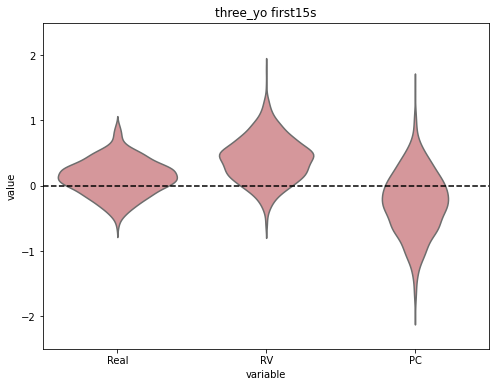

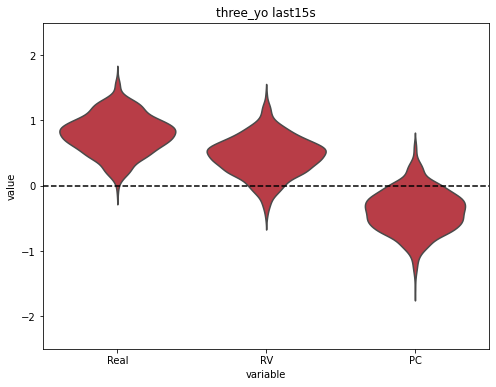

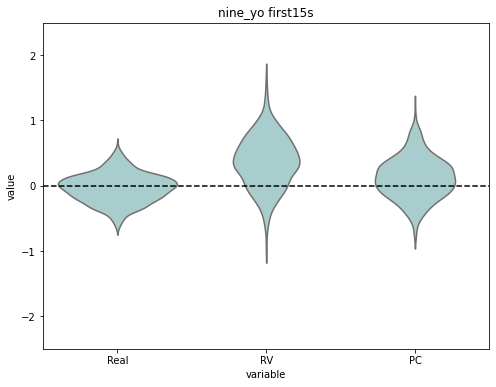

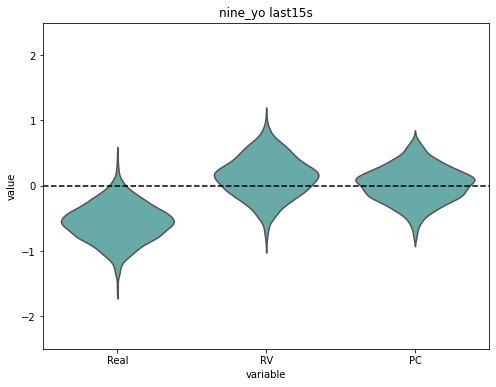

In [9]:
# preset
diff_dict = dict()
self_dict=dict()
other_dict=dict()
    
# cycle through participants
for ppt in participants:
    
    # preset
    diff_dict[ppt]=dict()
    self_dict[ppt]=dict() 
    other_dict[ppt]=dict()

    # load these CSVs (created above)
    file_name_right='%s/%s_%s_subfields_%s.csv' %(outputdir,hash_id_dict[ppt],'Right',FEAT)
    file_name_left='%s/%s_%s_subfields_%s.csv' %(outputdir,hash_id_dict[ppt],'Left',FEAT)

    # actually load the files (created above)
    right_hipp_csv=pd.read_csv(file_name_right,header=None)
    left_hipp_csv=pd.read_csv(file_name_left,header=None)

    # collapse them
    all_hipp_subfields=np.hstack((np.array(right_hipp_csv)[:,:6],np.array(left_hipp_csv)[:,:6]))

    # average within hippocampal ROI
    mean_hipp_vals = np.nanmean(all_hipp_subfields,axis=1)
    
    # Cycle through conditions and halves to create an organized dictionary of self vs. other distributions
    conditions= ['Real','RV','PC']
    halves = ['first15s','last15s']

    # random seed for bootstrap resampling 
    np.random.seed(0)
    nPerm=1000

    num_comps=len(conditions) # correct for 3 conditions for multiple comparisons correction

    # cycle through conditions 
    for condition in conditions:
    
        # preset for conditions 
        diff_dict[ppt][condition]=dict()
        self_dict[ppt][condition]=dict() 
        other_dict[ppt][condition]=dict()

        # cycle through first half / second half 
        for half in halves:

            # get self and other based on the zstat lables 
            if ppt =='three_yo':
                # get the idxs
                self_idxs = [i for i in range(len(zstat_conds)) if 
                             '%s_%s_%s' %(hash_id_dict[ppt].split('_')[1],condition,half) in zstat_conds[i]]
                other_idxs= [i for i in range(len(zstat_conds)) if 
                             '%s_%s_%s' %(hash_id_dict['nine_yo'].split('_')[1],condition,half) in zstat_conds[i]]
            elif ppt=='nine_yo':
                 # get the idxs
                self_idxs = [i for i in range(len(zstat_conds)) if 
                             '%s_%s_%s' %(hash_id_dict[ppt].split('_')[1],condition,half) in zstat_conds[i]]
                other_idxs= [i for i in range(len(zstat_conds)) if 
                             '%s_%s_%s' %(hash_id_dict['three_yo'].split('_')[1],condition,half) in zstat_conds[i]]

            # get the hipp vals
            self_vals= mean_hipp_vals[self_idxs]
            other_vals = mean_hipp_vals[other_idxs]

            # calculate the distribution via bootstrap resampling 
            self_bs_dist= bootstrap_dist(self_vals)
            other_bs_dist= bootstrap_dist(other_vals)

            # subtract for the difference 
            diff_dist = np.array(self_bs_dist) - np.array(other_bs_dist)

            if np.mean(diff_dist)>0:
                pval = sum(diff_dist<0)/(nPerm)*2*num_comps # multiply by 2 for twosided test and 3 for comparisons correction
            else:
                pval = sum(diff_dist>0)/(nPerm)*2*num_comps # multiply by 2 for twosided test and 3 for comparisons correction


            print('%s %s Self > Other %s: M=%0.4f, CI =[%0.4f, %0.4f]; p = %0.4f' %(ppt,condition,half,
                                                                   np.nanmean(diff_dist),
                                                                   np.percentile(diff_dist, 2.5), 
                                                                np.percentile(diff_dist, 97.5),
                                                                   pval))

            # save ! 
            diff_dict[ppt][condition][half]=diff_dist

            # add a non subtracted dictionary 
            self_dict[ppt][condition][half]=self_bs_dist
            other_dict[ppt][condition][half]=other_bs_dist

    # explode for plotting purposes 
    diff_df = pd.DataFrame(diff_dict[ppt]).reset_index().melt(id_vars='index')
    explode_df = pd.concat([diff_df[col].explode() for col in diff_df],
                    axis="columns")
    explode_df['value']=explode_df['value'].astype('float64')

    # Plot the whole hippocampus -- separate the halves though 
    for i, half in enumerate(np.unique(explode_df['index'])):
        fig = plt.figure(figsize=(8,6))
        plt.title('%s %s' %(ppt,half))
        sns.violinplot(x='variable',y='value',data=explode_df[explode_df['index']==half],
                       color=color_palettes[ppt][i],inner=None)
        plt.axhline(0,linestyle='dashed',color='k')
        plt.ylim(-2.5,2.5)
        fig.savefig('plots/%s_whole_hipp_%s.svg' %(ppt,half))
        
    print()

three_yo Real last15s self: M=0.04, CI =[-0.35, 0.41]; p = 5.112
three_yo Real last15s other: M=-0.75, CI =[-1.22, -0.28]; p = 0.000
three_yo RV last15s self: M=-0.14, CI =[-0.64, 0.33]; p = 3.432
three_yo RV last15s other: M=-0.60, CI =[-0.97, -0.24]; p = 0.000
three_yo PC last15s self: M=-0.56, CI =[-1.04, -0.07]; p = 0.144
three_yo PC last15s other: M=-0.17, CI =[-0.59, 0.23]; p = 2.328

nine_yo Real last15s self: M=-0.15, CI =[-0.53, 0.22]; p = 2.604
nine_yo Real last15s other: M=0.42, CI =[0.04, 0.82]; p = 0.144
nine_yo RV last15s self: M=0.01, CI =[-0.34, 0.34]; p = 5.856
nine_yo RV last15s other: M=-0.13, CI =[-0.61, 0.38]; p = 3.480
nine_yo PC last15s self: M=-0.48, CI =[-0.92, -0.08]; p = 0.108
nine_yo PC last15s other: M=-0.51, CI =[-0.83, -0.20]; p = 0.012



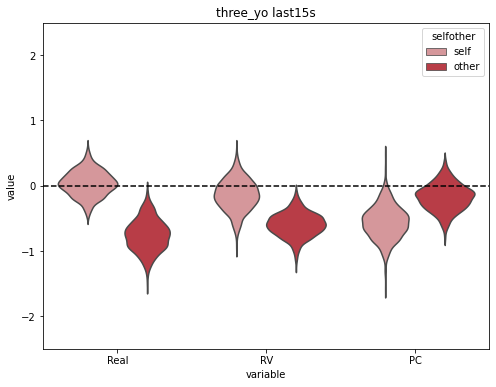

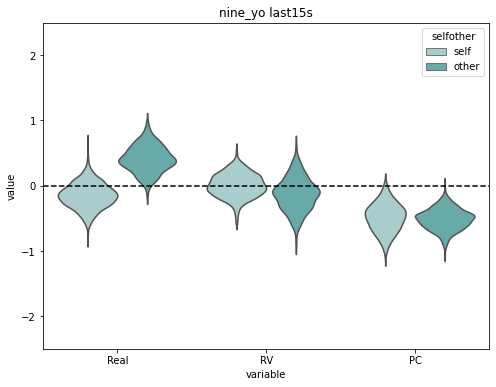

In [10]:
# What about the self and other separately?
half='last15s' # focus on the second half 

# cycle through participants
for ppt in participants:
    
    # separate self and other as well 
    self_df = pd.DataFrame(self_dict[ppt]).reset_index().melt(id_vars='index')
    self_df['selfother']=np.repeat('self',len(self_df))
    other_df = pd.DataFrame(other_dict[ppt]).reset_index().melt(id_vars='index')
    other_df['selfother']=np.repeat('other',len(self_df))
    self_other_df = pd.concat([self_df,other_df]).reset_index().drop(columns='level_0')

    # explode for plotting purposes 
    explode_df = pd.concat([self_other_df[col].explode() for col in self_other_df],
                    axis="columns")
    explode_df['value']=explode_df['value'].astype('float64')

    # Plot the whole hippocampus for the second half 
    fig = plt.figure(figsize=(8,6))

    plt.title('%s %s' %(ppt,half))
    sns.violinplot(x='variable',y='value',hue='selfother',data=explode_df[explode_df['index']==half],
                   palette=color_palettes[ppt],inner=None)
    plt.axhline(0,linestyle='dashed',color='k')
    plt.ylim(-2.5,2.5)
    fig.savefig('plots/%s_whole_hipp_self_other.svg' %(ppt))

    # print the values 
    for condition in ['Real','RV','PC']:
        for selfother in ['self','other']:

            values=explode_df[(explode_df['index']==half)*(explode_df['selfother']==selfother)*(explode_df['variable']==condition)].value

            if np.mean(values)>0:
                pval = sum(values<0)/(nPerm)*2*num_comps*2  # multiply by 2 for two-sided test, number of comparisons, self/other
            else:
                pval = sum(values>0)/(nPerm)*2*num_comps*2 # multiply by 2 for two-sided test, number of comparisons, self/other


            print('%s %s %s %s: M=%0.2f, CI =[%0.2f, %0.2f]; p = %0.3f' %(ppt,condition,half,selfother,
                                                                       np.nanmean(values),
                                                                       np.percentile(values, 2.5), 
                                                                    np.percentile(values, 97.5),
                                                                       pval))
    print()

### MTL 
Run the same analysis as above, but now with the MTL instead of hippocampus

three_yo Real Self > Other first15s: M=0.2139, CI =[-0.1283, 0.5846]; p = 0.7500
three_yo Real Self > Other last15s: M=0.2778, CI =[-0.0973, 0.6339]; p = 0.4320
three_yo RV Self > Other first15s: M=0.3160, CI =[-0.1253, 0.7497]; p = 0.4620
three_yo RV Self > Other last15s: M=0.2791, CI =[-0.0839, 0.6277]; p = 0.4140
three_yo PC Self > Other first15s: M=-0.1025, CI =[-0.7632, 0.4987]; p = 2.3220
three_yo PC Self > Other last15s: M=-0.1598, CI =[-0.5141, 0.2130]; p = 1.1820

nine_yo Real Self > Other first15s: M=-0.0371, CI =[-0.5380, 0.4154]; p = 2.7180
nine_yo Real Self > Other last15s: M=-0.3069, CI =[-0.8285, 0.1915]; p = 0.7500
nine_yo RV Self > Other first15s: M=0.3626, CI =[-0.1629, 0.8799]; p = 0.5280
nine_yo RV Self > Other last15s: M=0.2876, CI =[-0.0750, 0.6558]; p = 0.3900
nine_yo PC Self > Other first15s: M=0.3783, CI =[-0.1044, 0.8805]; p = 0.3720
nine_yo PC Self > Other last15s: M=0.0481, CI =[-0.3309, 0.4156]; p = 2.3340



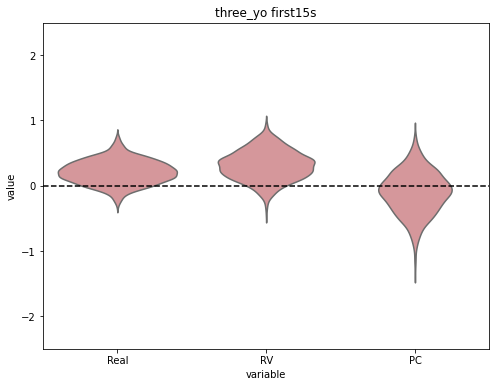

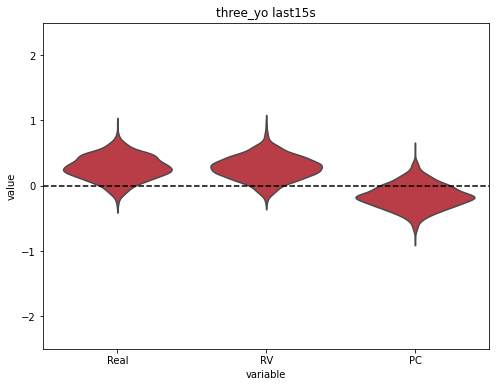

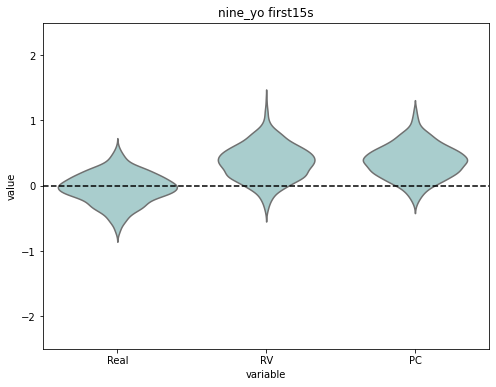

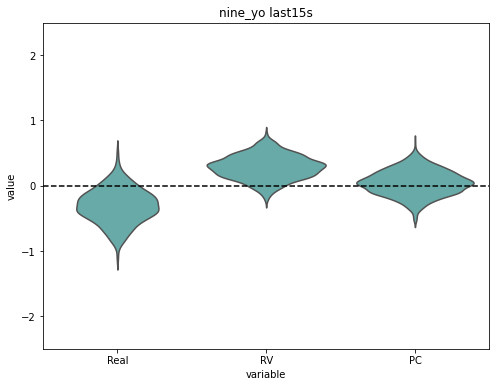

In [11]:
# preset
diff_dict = dict()
self_dict=dict()
other_dict=dict()
    
# cycle through participants
for ppt in participants:
    
    # preset
    diff_dict[ppt]=dict()
    self_dict[ppt]=dict() 
    other_dict[ppt]=dict()

    # load these CSVs (created above)
    file_name_right='%s/%s_%s_subfields_%s.csv' %(outputdir,hash_id_dict[ppt],'Right',FEAT)
    file_name_left='%s/%s_%s_subfields_%s.csv' %(outputdir,hash_id_dict[ppt],'Left',FEAT)

    # actually load the files (created above)
    right_hipp_csv=pd.read_csv(file_name_right,header=None)
    left_hipp_csv=pd.read_csv(file_name_left,header=None)

    # collapse them
    all_mtl_subfields=np.hstack((np.array(right_hipp_csv)[:,6:],np.array(left_hipp_csv)[:,6:]))

    # average within MTL ROI
    mean_mtl_vals = np.nanmean(all_mtl_subfields,axis=1)

    # Cycle through conditions and halves to create an organized dictionary of self vs. other distributions
    conditions= ['Real','RV','PC']
    halves = ['first15s','last15s']

    # random seed for bootstrap resampling 
    np.random.seed(0)
    nPerm=1000

    num_comps=len(conditions) # correct for 3 conditions for multiple comparisons correction

    # cycle through conditions 
    for condition in conditions:
    
        # preset for conditions 
        diff_dict[ppt][condition]=dict()
        self_dict[ppt][condition]=dict() 
        other_dict[ppt][condition]=dict()

        # cycle through first half / second half 
        for half in halves:

           # get self and other based on the zstat lables 
            if ppt =='three_yo':
                # get the idxs
                self_idxs = [i for i in range(len(zstat_conds)) if 
                             '%s_%s_%s' %(hash_id_dict[ppt].split('_')[1],condition,half) in zstat_conds[i]]
                other_idxs= [i for i in range(len(zstat_conds)) if 
                             '%s_%s_%s' %(hash_id_dict['nine_yo'].split('_')[1],condition,half) in zstat_conds[i]]
            elif ppt=='nine_yo':
                 # get the idxs
                self_idxs = [i for i in range(len(zstat_conds)) if 
                             '%s_%s_%s' %(hash_id_dict[ppt].split('_')[1],condition,half) in zstat_conds[i]]
                other_idxs= [i for i in range(len(zstat_conds)) if 
                             '%s_%s_%s' %(hash_id_dict['three_yo'].split('_')[1],condition,half) in zstat_conds[i]]

            # get the hipp vals
            self_vals= mean_mtl_vals[self_idxs]
            other_vals = mean_mtl_vals[other_idxs]

            # calculate the distribution via bootstrap resampling 
            self_bs_dist= bootstrap_dist(self_vals)
            other_bs_dist= bootstrap_dist(other_vals)

            # subtract for the difference 
            diff_dist = np.array(self_bs_dist) - np.array(other_bs_dist)

            if np.mean(diff_dist)>0:
                pval = sum(diff_dist<0)/(nPerm)*2*num_comps # multiply by 2 for twosided test and 3 for comparisons correction
            else:
                pval = sum(diff_dist>0)/(nPerm)*2*num_comps # multiply by 2 for twosided test and 3 for comparisons correction


            print('%s %s Self > Other %s: M=%0.4f, CI =[%0.4f, %0.4f]; p = %0.4f' %(ppt,condition,half,
                                                                   np.nanmean(diff_dist),
                                                                   np.percentile(diff_dist, 2.5), 
                                                                np.percentile(diff_dist, 97.5),
                                                                   pval))

            # save ! 
            diff_dict[ppt][condition][half]=diff_dist

            # add a non subtracted dictionary 
            self_dict[ppt][condition][half]=self_bs_dist
            other_dict[ppt][condition][half]=other_bs_dist

    # explode for plotting purposes 
    diff_df = pd.DataFrame(diff_dict[ppt]).reset_index().melt(id_vars='index')
    explode_df = pd.concat([diff_df[col].explode() for col in diff_df],
                    axis="columns")
    explode_df['value']=explode_df['value'].astype('float64')

    # Plot the whole hippocampus -- separate the halves though 
    for i, half in enumerate(np.unique(explode_df['index'])):
        fig = plt.figure(figsize=(8,6))
        plt.title('%s %s' %(ppt,half))
        sns.violinplot(x='variable',y='value',data=explode_df[explode_df['index']==half],
                       color=color_palettes[ppt][i],inner=None)
        plt.axhline(0,linestyle='dashed',color='k')
        plt.ylim(-2.5,2.5)
        fig.savefig('plots/%s_whole_mtl_%s.svg' %(ppt,half))
        
    print()

### Hippocampal subfields 

CA1
three_yo Real Self > Other last15s: M=0.6565, CI =[-0.0776, 1.3751]; p = 1.4040
three_yo RV Self > Other last15s: M=0.4857, CI =[-0.2297, 1.2778]; p = 4.7160
three_yo PC Self > Other last15s: M=-0.7001, CI =[-1.4335, 0.0487]; p = 1.2600

CA2
three_yo Real Self > Other last15s: M=0.9783, CI =[0.2110, 1.6880]; p = 0.0720
three_yo RV Self > Other last15s: M=0.4016, CI =[-0.3013, 1.1346]; p = 5.4720
three_yo PC Self > Other last15s: M=-0.5041, CI =[-1.2182, 0.2335]; p = 3.6000

CA3
three_yo Real Self > Other last15s: M=0.7485, CI =[0.0872, 1.3711]; p = 0.3600
three_yo RV Self > Other last15s: M=0.3908, CI =[-0.2017, 1.0160]; p = 4.0680
three_yo PC Self > Other last15s: M=-0.4587, CI =[-1.0682, 0.1882]; p = 3.4560

DG
three_yo Real Self > Other last15s: M=0.8477, CI =[0.2279, 1.4407]; p = 0.0360
three_yo RV Self > Other last15s: M=0.3429, CI =[-0.2973, 1.0010]; p = 5.6880
three_yo PC Self > Other last15s: M=-0.3445, CI =[-0.9527, 0.2809]; p = 5.5800

Sub
three_yo Real Self > Other last1

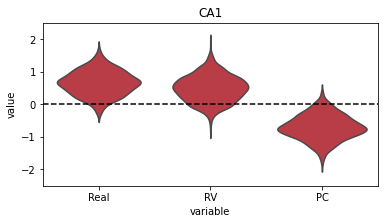

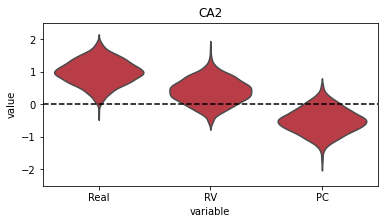

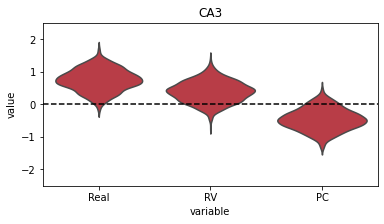

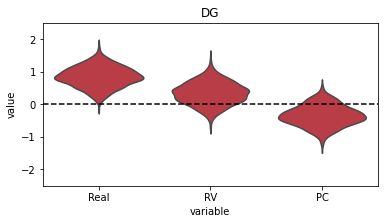

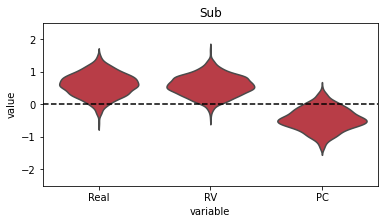

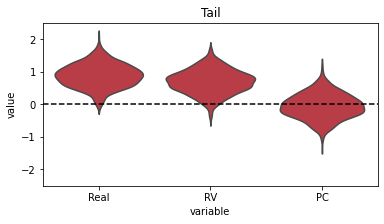

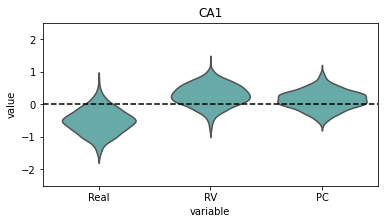

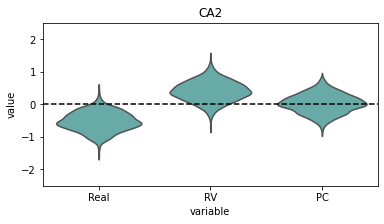

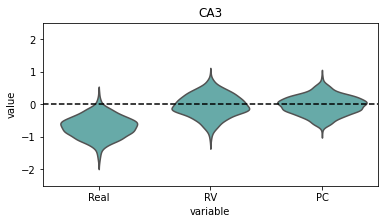

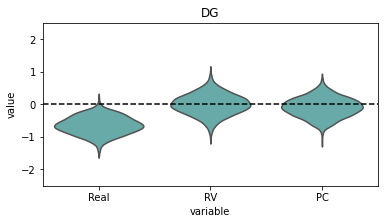

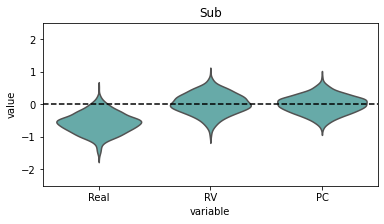

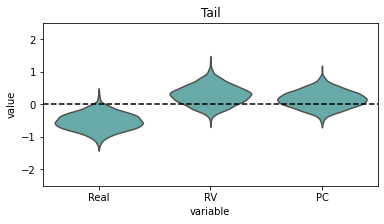

In [12]:
for ppt in participants:

    # Now make the plots for the subfields (only last 15s)
    for subfield in subfield_idx_dict.keys():
        print(subfield)

         # load these CSVs (created above)
        file_name_right='%s/%s_%s_subfields_%s.csv' %(outputdir,hash_id_dict[ppt],'Right',FEAT)
        file_name_left='%s/%s_%s_subfields_%s.csv' %(outputdir,hash_id_dict[ppt],'Left',FEAT)

        # actually load the files (created above)
        right_hipp_csv=pd.read_csv(file_name_right,header=None)
        left_hipp_csv=pd.read_csv(file_name_left,header=None)
    
        avg_subfield_vals =np.stack((np.array(right_hipp_csv)[:,subfield_idx_dict[subfield]],
                                  np.array(left_hipp_csv)[:,subfield_idx_dict[subfield]]))
        avg_subfield_vals = np.nanmean(avg_subfield_vals,axis=0)

        zstat_conds=np.array(zstat_conds)

        conditions= ['Real','RV','PC']
        halves = ['last15s']

        np.random.seed(0)
        nPerm=1000

        diff_dict_subfield = dict()

        for condition in conditions:
            diff_dict_subfield[condition]=dict()
            for half in halves:

               # get self and other based on the zstat lables 
                if ppt =='three_yo':
                    # get the idxs
                    self_idxs = [i for i in range(len(zstat_conds)) if 
                                 '%s_%s_%s' %(hash_id_dict[ppt].split('_')[1],condition,half) in zstat_conds[i]]
                    other_idxs= [i for i in range(len(zstat_conds)) if 
                                 '%s_%s_%s' %(hash_id_dict['nine_yo'].split('_')[1],condition,half) in zstat_conds[i]]
                elif ppt=='nine_yo':
                     # get the idxs
                    self_idxs = [i for i in range(len(zstat_conds)) if 
                                 '%s_%s_%s' %(hash_id_dict[ppt].split('_')[1],condition,half) in zstat_conds[i]]
                    other_idxs= [i for i in range(len(zstat_conds)) if 
                                 '%s_%s_%s' %(hash_id_dict['three_yo'].split('_')[1],condition,half) in zstat_conds[i]]

                # get the hipp vals
                self_vals= avg_subfield_vals[self_idxs]
                other_vals = avg_subfield_vals[other_idxs]

                # calc the dist 
                self_bs_dist= bootstrap_dist(self_vals)
                other_bs_dist= bootstrap_dist(other_vals)

                # subtract for the difference 
                diff_dist = np.array(self_bs_dist) - np.array(other_bs_dist)

                if np.mean(diff_dist)>0:
                    pval = sum(diff_dist<0)/(nPerm)*2*num_comps*len(subfield_idx_dict)
                else:
                    pval = sum(diff_dist>0)/(nPerm)*2*num_comps*len(subfield_idx_dict)

                print('%s %s Self > Other %s: M=%0.4f, CI =[%0.4f, %0.4f]; p = %0.4f' %(ppt,condition,half,
                                                                   np.nanmean(diff_dist),
                                                                   np.percentile(diff_dist, 2.5), 
                                                                np.percentile(diff_dist, 97.5),
                                                                   pval))
                # save ! 
                diff_dict_subfield[condition][half]=diff_dist

        diff_df_subfield = pd.DataFrame(diff_dict_subfield).reset_index().melt(id_vars='index')
        explode_df_subfield = pd.concat([diff_df_subfield[col].explode() for col in diff_df_subfield],
                        axis="columns")
        explode_df_subfield['value']=explode_df_subfield['value'].astype('float64')
        explode_df_subfield.head()

        fig = plt.figure(figsize=(6,3))
        sns.violinplot(x='variable',y='value',data=explode_df_subfield,
                       color=color_palettes[ppt][1],inner=None)
        plt.axhline(0,linestyle='dashed',color='k')
        plt.ylim(-2.5,2.5)
        plt.title(subfield)
        fig.savefig('plots/%s_subfield_%s.svg' %(ppt,subfield))
        print()

ErC
three_yo Real Self > Other last15s: M=0.1315, CI =[-0.1609, 0.4114]; p = 4.3200
three_yo RV Self > Other last15s: M=0.1878, CI =[-0.1215, 0.5343]; p = 3.4800
three_yo PC Self > Other last15s: M=-0.1584, CI =[-0.4895, 0.1701]; p = 4.2960

PrC_35
three_yo Real Self > Other last15s: M=0.0992, CI =[-0.3014, 0.4982]; p = 7.4400
three_yo RV Self > Other last15s: M=0.1373, CI =[-0.3225, 0.5985]; p = 7.2240
three_yo PC Self > Other last15s: M=-0.1906, CI =[-0.6315, 0.2390]; p = 4.8480

PrC_36
three_yo Real Self > Other last15s: M=-0.0530, CI =[-0.2504, 0.1597]; p = 7.0320
three_yo RV Self > Other last15s: M=0.0839, CI =[-0.1199, 0.2976]; p = 5.0880
three_yo PC Self > Other last15s: M=0.0079, CI =[-0.2195, 0.2403]; p = 11.2800

PhC
three_yo Real Self > Other last15s: M=0.9042, CI =[0.0188, 1.7291]; p = 0.5040
three_yo RV Self > Other last15s: M=0.7237, CI =[0.0648, 1.3883]; p = 0.3840
three_yo PC Self > Other last15s: M=-0.3582, CI =[-0.9848, 0.2586]; p = 3.0720

ErC
nine_yo Real Self > Oth

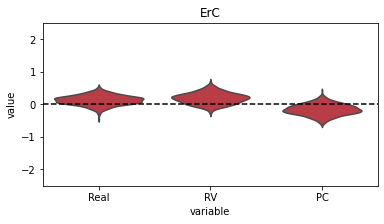

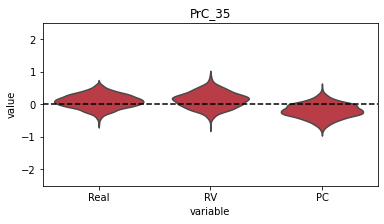

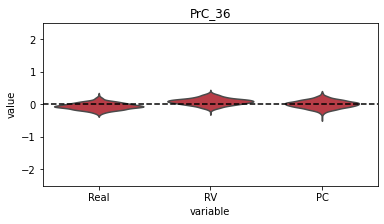

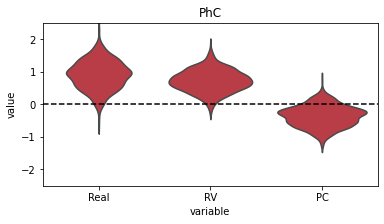

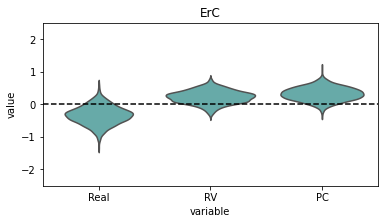

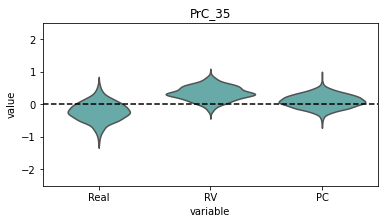

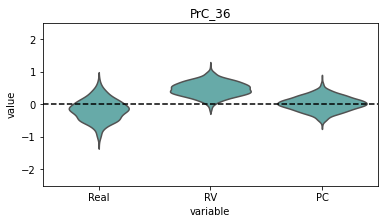

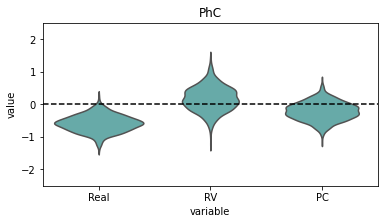

In [13]:
for ppt in participants:

    # Now make the plots for the subfields (only last 15s)
    for subfield in subregion_idx_dict.keys():
        print(subfield)

         # load these CSVs (created above)
        file_name_right='%s/%s_%s_subfields_%s.csv' %(outputdir,hash_id_dict[ppt],'Right',FEAT)
        file_name_left='%s/%s_%s_subfields_%s.csv' %(outputdir,hash_id_dict[ppt],'Left',FEAT)

        # actually load the files (created above)
        right_hipp_csv=pd.read_csv(file_name_right,header=None)
        left_hipp_csv=pd.read_csv(file_name_left,header=None)

        avg_subfield_vals =np.stack((np.array(right_hipp_csv)[:,subregion_idx_dict[subfield]],
                                  np.array(left_hipp_csv)[:,subregion_idx_dict[subfield]]))
        avg_subfield_vals = np.nanmean(avg_subfield_vals,axis=0)
        avg_subfield_vals.shape

        zstat_conds=np.array(zstat_conds)

        conditions= ['Real','RV','PC']
        halves = ['last15s']

        np.random.seed(0)
        nPerm=1000

        diff_dict_subfield = dict()

        for condition in conditions:
            diff_dict_subfield[condition]=dict()
            for half in halves:

               # get self and other based on the zstat lables 
                if ppt =='three_yo':
                    # get the idxs
                    self_idxs = [i for i in range(len(zstat_conds)) if 
                                 '%s_%s_%s' %(hash_id_dict[ppt].split('_')[1],condition,half) in zstat_conds[i]]
                    other_idxs= [i for i in range(len(zstat_conds)) if 
                                 '%s_%s_%s' %(hash_id_dict['nine_yo'].split('_')[1],condition,half) in zstat_conds[i]]
                elif ppt=='nine_yo':
                     # get the idxs
                    self_idxs = [i for i in range(len(zstat_conds)) if 
                                 '%s_%s_%s' %(hash_id_dict[ppt].split('_')[1],condition,half) in zstat_conds[i]]
                    other_idxs= [i for i in range(len(zstat_conds)) if 
                                 '%s_%s_%s' %(hash_id_dict['three_yo'].split('_')[1],condition,half) in zstat_conds[i]]

                # get the hipp vals
                self_vals= avg_subfield_vals[self_idxs]
                other_vals = avg_subfield_vals[other_idxs]

                # calc the dist 
                self_bs_dist= bootstrap_dist(self_vals)
                other_bs_dist= bootstrap_dist(other_vals)

                # subtract for the difference 
                diff_dist = np.array(self_bs_dist) - np.array(other_bs_dist)

                if np.mean(diff_dist)>0:
                    pval = sum(diff_dist<0)/(nPerm)*2*num_comps*len(subregion_idx_dict)
                else:
                    pval = sum(diff_dist>0)/(nPerm)*2*num_comps*len(subregion_idx_dict)

                print('%s %s Self > Other %s: M=%0.4f, CI =[%0.4f, %0.4f]; p = %0.4f' %(ppt,condition,half,
                                                                   np.nanmean(diff_dist),
                                                                   np.percentile(diff_dist, 2.5), 
                                                                np.percentile(diff_dist, 97.5),
                                                                   pval))
                # save ! 
                diff_dict_subfield[condition][half]=diff_dist

        diff_df_subfield = pd.DataFrame(diff_dict_subfield).reset_index().melt(id_vars='index')
        explode_df_subfield = pd.concat([diff_df_subfield[col].explode() for col in diff_df_subfield],
                        axis="columns")
        explode_df_subfield['value']=explode_df_subfield['value'].astype('float64')
        explode_df_subfield.head()

        fig = plt.figure(figsize=(6,3))
        sns.violinplot(x='variable',y='value',data=explode_df_subfield,
                       color=color_palettes[ppt][1],inner=None)
        plt.axhline(0,linestyle='dashed',color='k')
        plt.ylim(-2.5,2.5)
        plt.title(subfield)
        fig.savefig('plots/%s_subfield_%s.svg' %(ppt,subfield))
        print()

## Self vs. Other in the whole brain <a id='selfother_whole'></a> 
These outputs were created by running scripts/Saycam/run_searchlight.sh with the inputs: ppt condition half
Cluster correction was then run on the command line using fsl-cluster with a t value of 3.1, p value of 0.05.

three_yo Real last15s selfvsother
   Cluster Index  Voxels       P  -log10(P)   MAX  MAX X (vox)  MAX Y (vox)  \
0              2      28  0.0383       1.42  4.60           23           33   
1              1      27  0.0442       1.35  4.05           23           45   

   MAX Z (vox)  COG X (vox)  COG Y (vox)  COG Z (vox)  
0           40         24.4         34.3         39.5  
1           34         21.6         46.4         33.7  

three_yo RV last15s selfvsother
   Cluster Index  Voxels       P  -log10(P)   MAX  MAX X (vox)  MAX Y (vox)  \
0              1      27  0.0332       1.48  4.28           42           53   

   MAX Z (vox)  COG X (vox)  COG Y (vox)  COG Z (vox)  
0           31         42.9         50.6         31.8  

three_yo PC last15s selfvsother
No clusters!
nine_yo Real last15s selfvsother
No clusters!
nine_yo RV last15s selfvsother
No clusters!
nine_yo PC last15s selfvsother
No clusters!


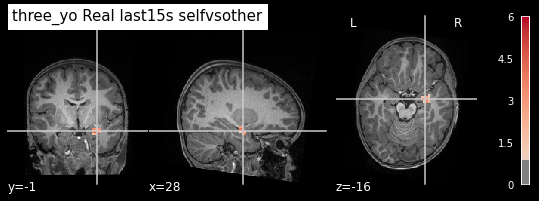

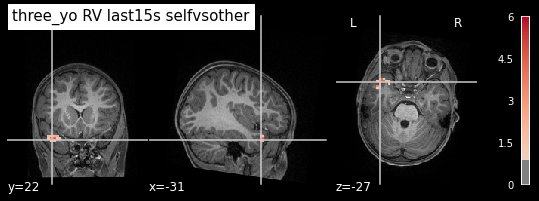

In [14]:
contrast='selfvsother' # selfvsother, othervsself

# first, the self > other 
for ppt in participants:
    for condition in ['Real','RV','PC']:
        
        print('%s %s %s %s' %(ppt,condition,half,contrast))
        clusters = pd.read_csv('niftis/%s_%s_%s_%s_cluster_t%s_corrp.txt' %(hash_id_dict[ppt],contrast,condition,half,tval),delimiter='\t')
        if len(clusters)==0:
            print('No clusters!')
            continue
        else:
            print(clusters)


        # load the file
        zstat_file = '%s/scripts/Saycam/niftis/%s_%s_%s_%s_cluster_t%s_corrp.nii.gz' % (base_dir,
                                                                                        hash_id_dict[ppt],contrast,condition,half,tval)

        # load the background highrest image 
        highres_file=nib.load('%s/subjects/%s/analysis/secondlevel/highres_original.nii.gz' %(base_dir,hash_id_dict[ppt]))

        # plot it! 
        plotting.plot_stat_map(zstat_file,bg_img=highres_file,threshold=0.95, # already thresholded but this looks better
                               dim=-0.75,vmax=6,cmap='coolwarm',title='%s %s %s %s' %(ppt,condition,half,contrast))   
        print()

three_yo Real last15s othervsself
   Cluster Index  Voxels         P  -log10(P)   MAX  MAX X (vox)  MAX Y (vox)  \
0             10     116  0.000003       5.59  4.41           45           28   
1              9      85  0.000049       4.31  4.54           19           62   
2              8      65  0.000396       3.40  5.61           39           33   
3              7      58  0.000866       3.06  4.76           12           30   
4              6      44  0.004570       2.34  4.18           44           31   
5              5      40  0.007580       2.12  4.15           29           18   
6              4      40  0.007580       2.12  4.66           25           68   
7              3      36  0.012800       1.89  4.77           26           23   
8              2      33  0.019100       1.72  4.65           18           20   
9              1      29  0.033200       1.48  4.48           39           66   

   MAX Z (vox)  COG X (vox)  COG Y (vox)  COG Z (vox)  
0           34    

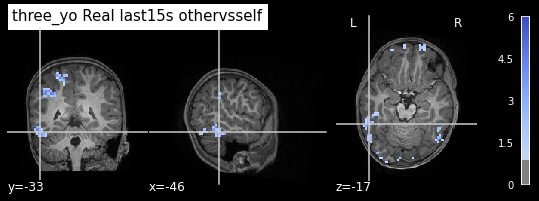

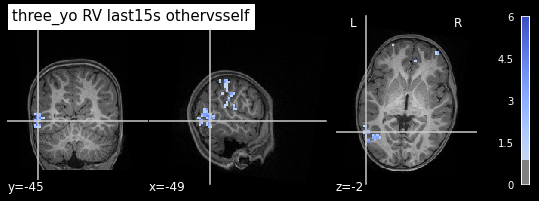

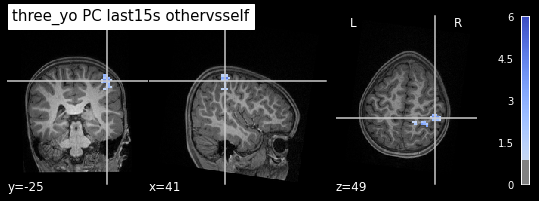

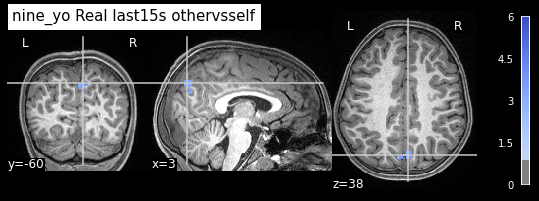

In [15]:
contrast='othervsself' # selfvsother, othervsself

# then, the other > self 
for ppt in participants:
    for condition in ['Real','RV','PC']:
        
        print('%s %s %s %s' %(ppt,condition,half,contrast))
        clusters = pd.read_csv('niftis/%s_%s_%s_%s_cluster_t%s_corrp.txt' %(hash_id_dict[ppt],contrast,condition,half,tval),delimiter='\t')
        if len(clusters)==0:
            print('No clusters!')
            continue
        else:
            print(clusters)


        # load the file
        zstat_file = '%s/scripts/Saycam/niftis/%s_%s_%s_%s_cluster_t%s_corrp.nii.gz' % (base_dir,
                                                                                        hash_id_dict[ppt],contrast,condition,half,tval)

        # load the background highrest image 
        highres_file=nib.load('%s/subjects/%s/analysis/secondlevel/highres_original.nii.gz' %(base_dir,hash_id_dict[ppt]))

        # plot it! 
        plotting.plot_stat_map(zstat_file,bg_img=highres_file,threshold=0.95, # already thresholded but this looks better
                               dim=-0.75,vmax=6,cmap='coolwarm_r',title='%s %s %s %s' %(ppt,condition,half,contrast))   
        print()

### Control: Visual activation

three_yo All visual contrast
   Cluster Index  Voxels             P  -log10(P)    MAX  MAX X (vox)  \
0              4    3474  1.170000e-28      27.90  39.20           27   
1              3     723  4.380000e-10       9.36  24.60           39   
2              2     623  3.900000e-09       8.41  23.00           13   
3              1      74  3.080000e-02       1.51   8.36           11   

   MAX Y (vox)  MAX Z (vox)  COG X (vox)  COG Y (vox)  COG Z (vox)  
0           25           33         29.3         24.4         37.0  
1           37           44         44.0         42.0         39.3  
2           42           40         13.5         43.0         38.9  
3           54           41         13.8         56.7         35.5  

three_yo Self visual contrast
   Cluster Index  Voxels             P  -log10(P)   MAX  MAX X (vox)  \
0              3    2744  1.240000e-24      23.90  29.5           27   
1              2     491  5.960000e-08       7.22  16.0           39   
2            

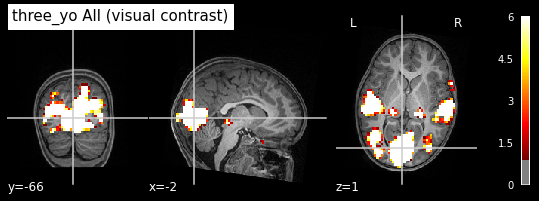

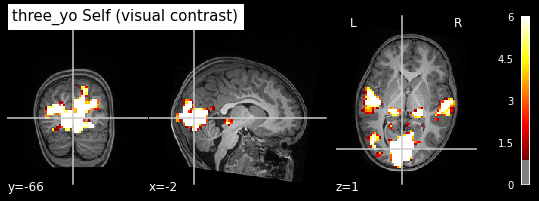

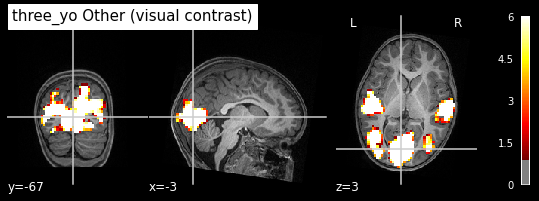

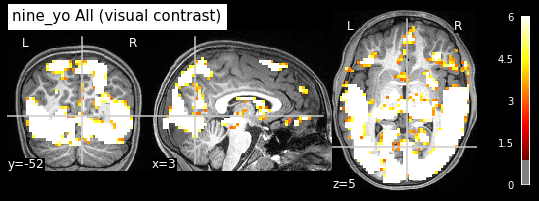

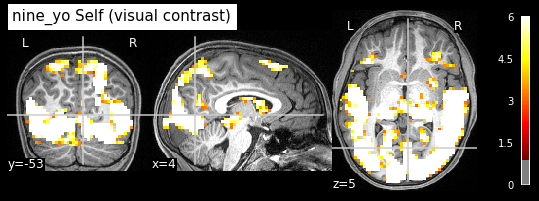

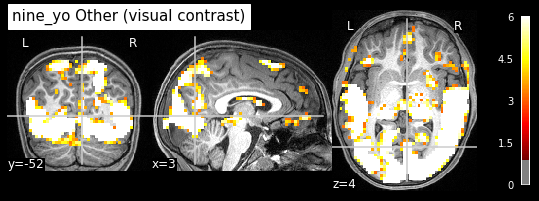

In [16]:
# what about visual activation? 
for ppt in participants:
    for condition in ['All','Self','Other']:
        
        print('%s %s visual contrast' %(ppt,condition))
        clusters = pd.read_csv('%s/scripts/Saycam/niftis/%s_visual_%s_cluster_t%s_corrp.txt' %(base_dir,hash_id_dict[ppt],condition,tval),delimiter='\t')
        if len(clusters)==0:
            print('No clusters!')
            continue
        else:
            print(clusters)


        # load the file
        zstat_file = '%s/scripts/Saycam/niftis/%s_visual_%s_cluster_t%s_corrp.nii.gz' % (base_dir,
                                                                                        hash_id_dict[ppt],condition,tval)

        # load the background highrest image 
        highres_file=nib.load('%s/subjects/%s/analysis/secondlevel/highres_original.nii.gz' %(base_dir,hash_id_dict[ppt]))

        # plot it! 
        plotting.plot_stat_map(zstat_file,bg_img=highres_file,threshold=0.95, # already thresholded but this looks better
                               dim=-0.75,vmax=6,cmap='cold_hot',title='%s %s (visual contrast)' %(ppt,condition))   
        print()